# Portuguese Bank Term Deposit Marketing: Analysis, Prediction & Recommendations

**Domain:** Finance / Banking  
**Data:** Direct phone-call marketing campaigns of a Portuguese bank (May 2008 – Nov 2010), `bank-additional-full.csv` (41,188 calls, 20 inputs, target `y` = subscribed to a term deposit).

**Contents**
1. Task 1: Data analysis report
2. Task 2: Predictive model
3. Task 3: Suggestions for the marketing team
4. Model comparison report
5. Report on challenges faced

> Data source: Moro, Cortez & Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42

In [2]:
# Dataset is in the Data folder next to this notebook
df = pd.read_csv('Data/bank-additional-full.csv', sep=';')
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# 1. Data Analysis Report (Task 1)

## 1.1 Structure and quality

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.select_dtypes('object').columns if c != 'y']
print('Numeric    :', num_cols)
print('Categorical:', cat_cols)
df[num_cols].describe().T

Numeric    : ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [5]:
print('Duplicate rows:', df.duplicated().sum())
print('True nulls    :', df.isnull().sum().sum())
unk = (df[cat_cols] == 'unknown').sum()
unk = pd.DataFrame({'unknown_count': unk, 'unknown_%': (unk / len(df) * 100).round(2)})
unk[unk.unknown_count > 0].sort_values('unknown_count', ascending=False)

Duplicate rows: 12
True nulls    : 0


,unknown_count,unknown_%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


**Observations:** there are no true nulls, but missing information is hidden behind the label `unknown` in six categorical columns (`default` is the worst). `pdays = 999` is a placeholder for "never contacted before", not a real number of days. There are a few exact duplicate rows.

## 1.2 Target variable

y
no     36548
yes     4640
Name: count, dtype: int64 
 y
no     88.73
yes    11.27
Name: count, dtype: float64


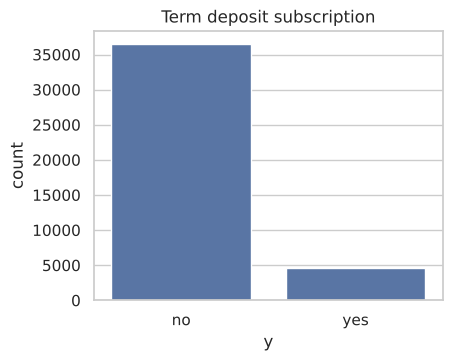

In [6]:
t = df['y'].value_counts()
print(t, '\n', (t / len(df) * 100).round(2))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x='y', data=df, ax=ax); ax.set_title('Term deposit subscription')
plt.show()

The target is heavily imbalanced (roughly 8 'no' for every 1 'yes'). A model that always says 'no' would be ~89% accurate yet useless, so **accuracy is not a suitable metric**. ROC-AUC, PR-AUC, recall, precision and F1 on the 'yes' class are used instead.

## 1.3 Numeric features

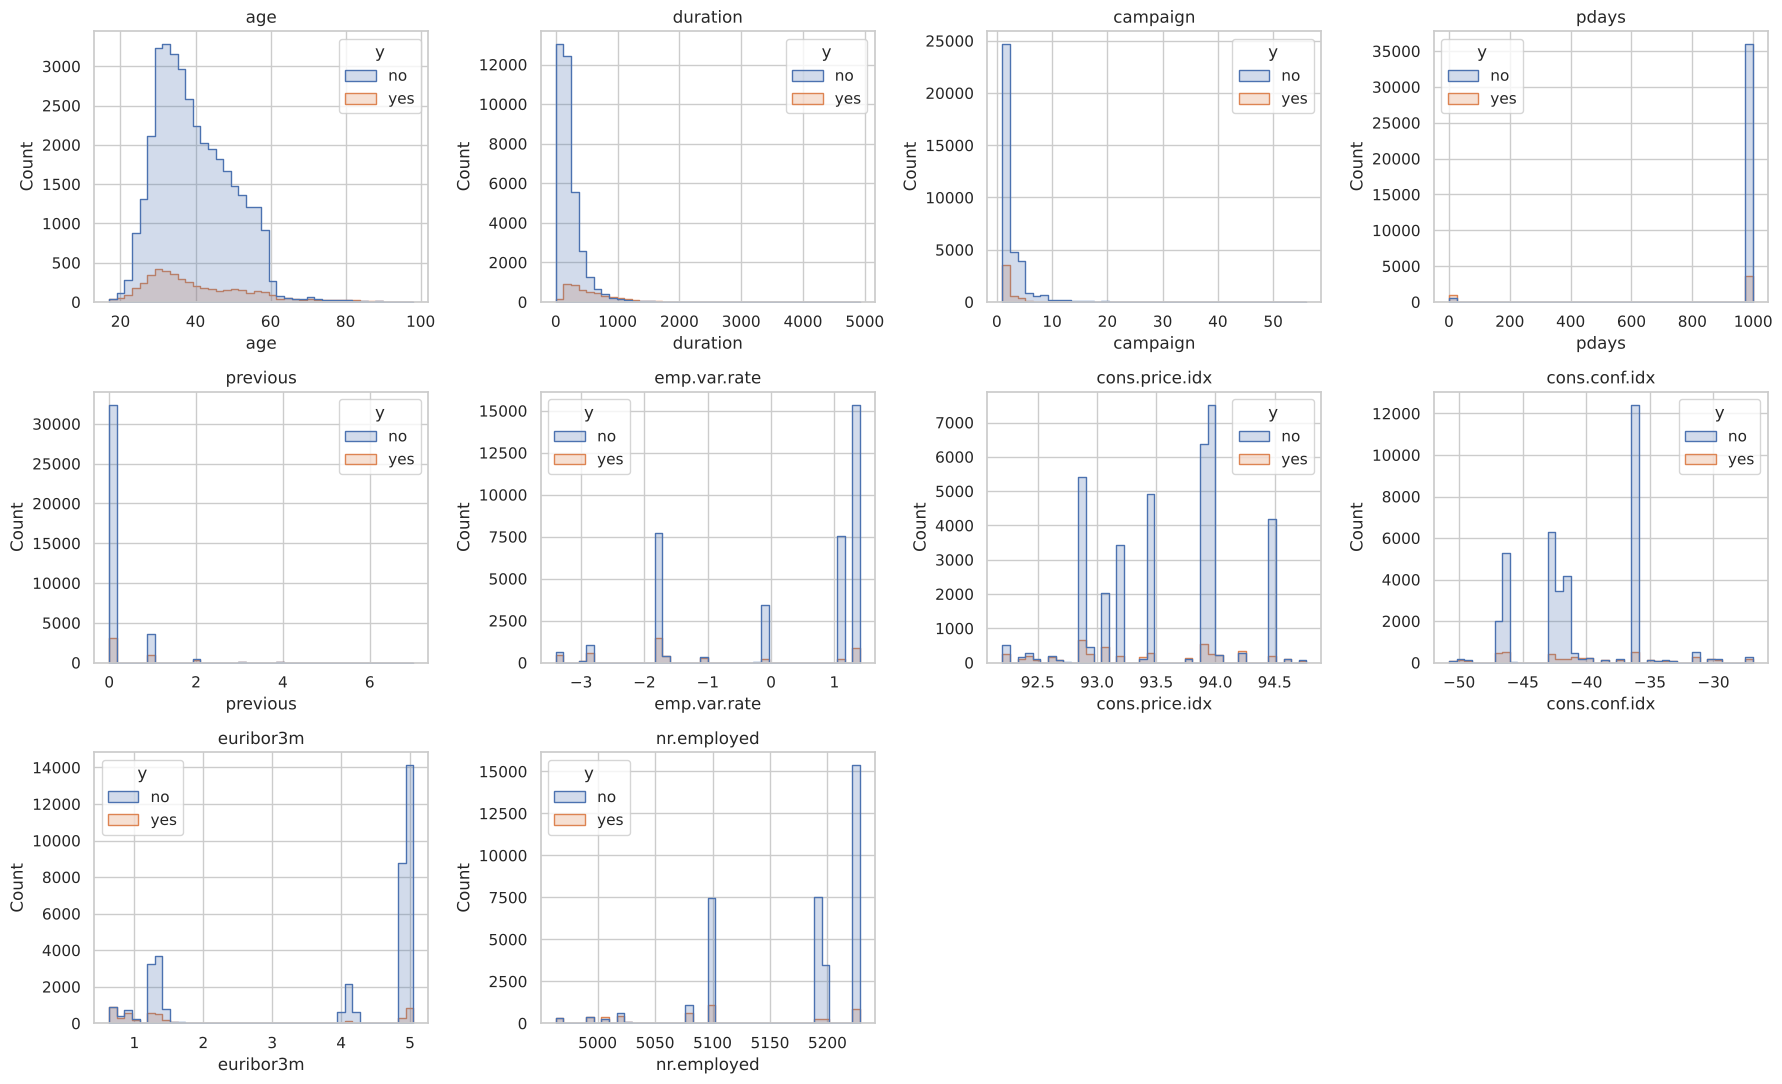

In [7]:
df['y_bin'] = (df['y'] == 'yes').astype(int)
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue='y', bins=40, ax=ax, element='step')
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]: ax.axis('off')
plt.tight_layout(); plt.show()

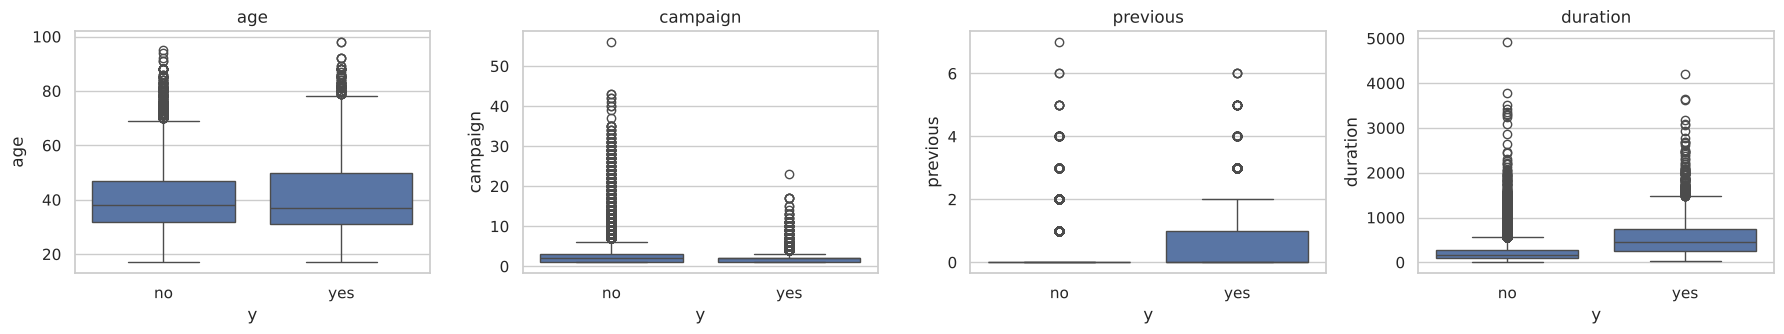

age         0.78
campaign    4.76
previous    3.83
duration    3.26
dtype: float64

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, c in zip(axes, ['age', 'campaign', 'previous', 'duration']):
    sns.boxplot(x='y', y=c, data=df, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()
df[['age','campaign','previous','duration']].skew().round(2)

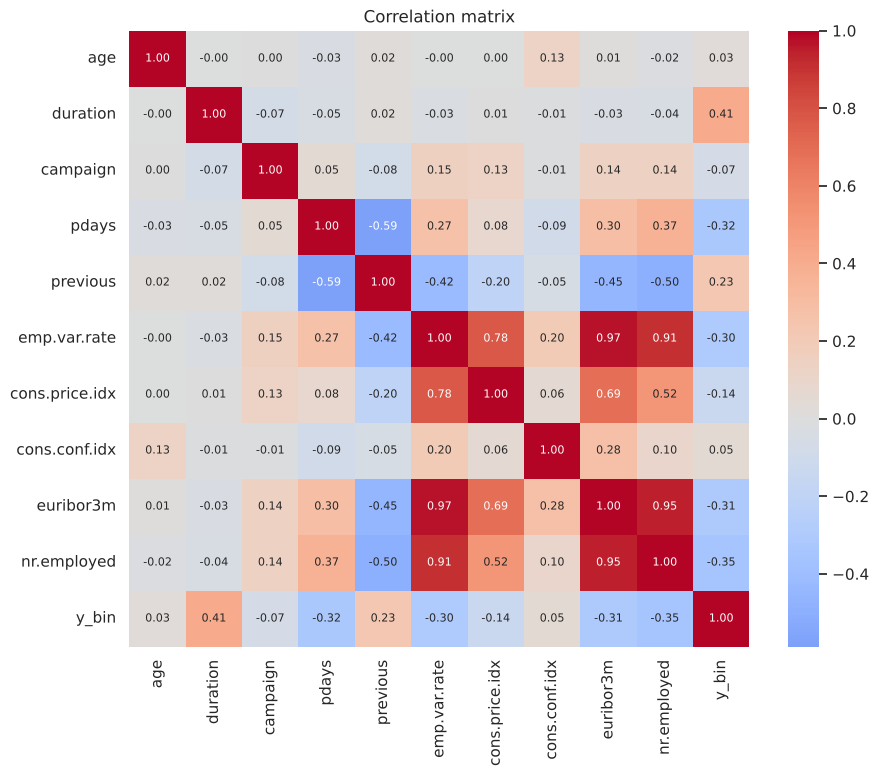

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols + ['y_bin']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation matrix'); plt.show()

**Observations**
- `campaign`, `previous` and `duration` are strongly right-skewed with many outliers (a few clients were called dozens of times).
- `emp.var.rate`, `euribor3m` and `nr.employed` are almost perfectly correlated with each other (multicollinearity); they all describe the same economic cycle.
- `duration` has the strongest link to `y`, but it is only known after the call ends, so it is leakage for a real predictive model.
- Fewer macro-economic "bad times" (lower euribor, lower employment-rate index) go with more subscriptions.

## 1.4 Categorical features vs. subscription rate

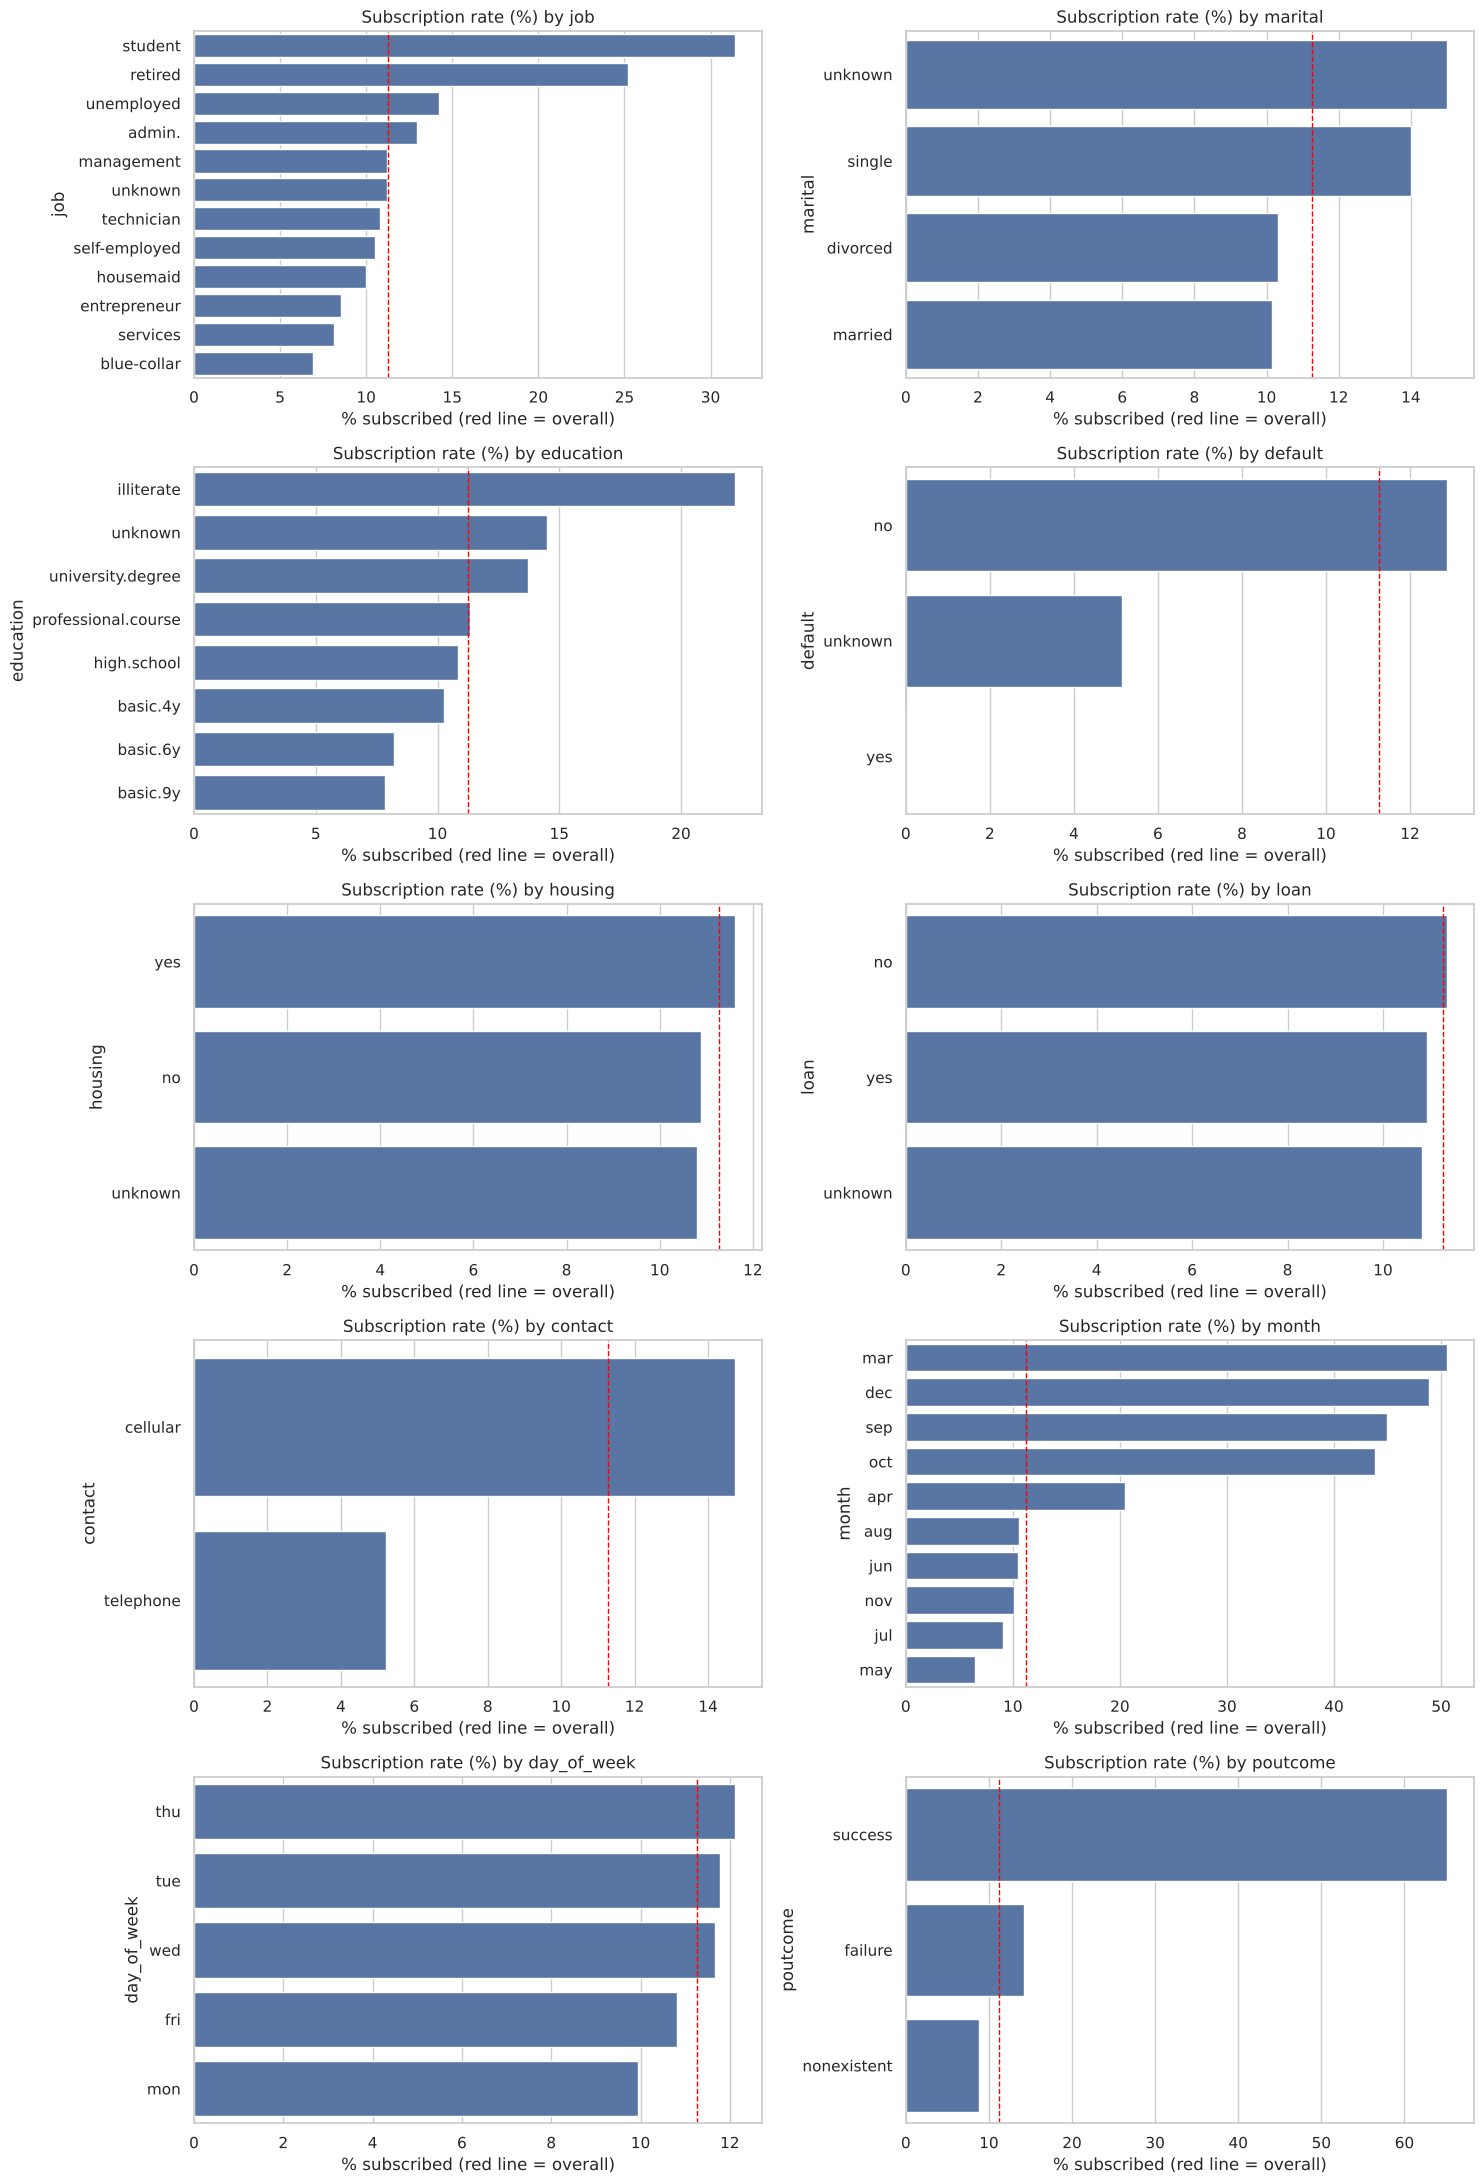

In [10]:
fig, axes = plt.subplots(5, 2, figsize=(15, 22))
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)['y_bin'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, orient='h')
    ax.axvline(df['y_bin'].mean() * 100, color='red', ls='--', lw=1)
    ax.set_title(f'Subscription rate (%) by {c}'); ax.set_xlabel('% subscribed (red line = overall)')
plt.tight_layout(); plt.show()

In [11]:
order = ['mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
m = df.groupby('month').agg(calls=('y_bin','size'), rate=('y_bin','mean')).reindex(order)
m['rate'] = (m['rate'] * 100).round(1)
m

,calls,rate
month,,
mar,546,50.5
apr,2632,20.5
may,13769,6.4
jun,5318,10.5
jul,7174,9.0
aug,6178,10.6
sep,570,44.9
oct,718,43.9
nov,4101,10.1


In [12]:
age_bins = pd.cut(df['age'], [17, 25, 35, 45, 55, 65, 100])
print((df.groupby(age_bins)['y_bin'].agg(['size', 'mean']).assign(mean=lambda x: (x['mean']*100).round(1))))
print()
print(df.groupby('poutcome')['y_bin'].agg(['size', 'mean']).assign(mean=lambda x: (x['mean']*100).round(1)))
print()
print(df.groupby(df['pdays'] != 999)['y_bin'].agg(['size', 'mean']).assign(mean=lambda x: (x['mean']*100).round(1)))

            size  mean
age                   
(17, 25]    1661  20.9
(25, 35]   14847  11.7
(35, 45]   12844   8.5
(45, 55]    8249   8.7
(55, 65]    2963  15.2
(65, 100]    619  46.8

              size  mean
poutcome                
failure       4252  14.2
nonexistent  35563   8.8
success       1373  65.1

        size  mean
pdays             
False  39673   9.3
True    1515  63.8


In [13]:
# How subscription changes with number of contacts in this campaign
c = df.assign(campaign_cap=df['campaign'].clip(upper=10)).groupby('campaign_cap')['y_bin'].agg(['size','mean'])
c['mean'] = (c['mean']*100).round(1); c

,size,mean
campaign_cap,,
1,17642,13.0
2,10570,11.5
3,5341,10.7
4,2651,9.4
5,1599,7.5
6,979,7.7
7,629,6.0
8,400,4.2
9,283,6.0


**Key insights (EDA)**  
- **Only 11.3% of calls ended in a subscription** (4,640 of 41,188), so the problem is imbalanced.
- **Channel matters:** cellular contacts convert at 14.7% vs 5.2% for landline telephone.
- **Past success is the strongest customer signal:** clients whose previous campaign succeeded subscribed 65.1% of the time (vs 8.8% for never-contacted clients). The 1,515 previously contacted clients convert at 63.8% overall.
- **Who subscribes:** students (31.4%) and retirees (25.2%) lead; blue-collar (6.9%) and services (8.1%) trail. By age, the under-25 (20.9%) and 55+ groups (15.2%; 46.8% for 65+, a small group of 619) are well above the 8–9% of ages 35–55. Higher education also goes with slightly higher rates.
- **Timing:** March, September, October and December convert at 44–51%, but with only 180–720 calls each. May has by far the most calls (13,769) and the lowest rate (6.4%).
- **Diminishing returns on repeat calls:** the subscription rate falls from 13.0% on the first contact to about 4% by the 10th.
- **Economic climate:** when euribor3m was at or below 1.5, 24% subscribed, against 4.8% when it was above 4. `euribor3m`, `emp.var.rate` and `nr.employed` are correlated at 0.91–0.97.
- `default`, `loan`, `housing` and `day_of_week` show little or no separation (e.g. housing/personal loan rates are within one point of each other). `default = yes` has only 3 rows.

# 2. Predictive Model (Task 2)

## 2.1 Preprocessing decisions
| Issue | Decision | Why |
|---|---|---|
| `duration` is unknown before a call | **Dropped** from the production model (kept only in a benchmark run) | Avoids leakage; the model must score customers *before* calling them |
| 12 duplicate rows | Removed | Would leak between train and test |
| `unknown` labels | Kept as their own category | `unknown` is informative (e.g. `default = unknown`) and avoids dropping up to ~20% of rows |
| `pdays = 999` | Replaced by a `previously_contacted` flag and 0 for the day count | 999 would distort distances and linear models |
| Skewed counts | Capped `campaign` at 99th percentile; `log1p` on `previous` | Limits outlier influence on linear models |
| Categoricals | One-hot encoding | Works for all model families |
| Numerics | Standardised (needed for Logistic Regression) | Harmless for tree models |
| Imbalance (11% yes) | Class weights (`balanced` / `scale_pos_weight`) and threshold tuning | Keeps all real data, no synthetic rows |

In [14]:
data = df.drop(columns=['y_bin']).drop_duplicates().reset_index(drop=True)

def engineer(d, drop_duration=True):
    d = d.copy()
    d['previously_contacted'] = (d['pdays'] != 999).astype(int)
    d['pdays'] = d['pdays'].replace(999, 0)
    d['campaign'] = d['campaign'].clip(upper=CAMPAIGN_CAP)
    d['previous'] = np.log1p(d['previous'])
    if drop_duration: d = d.drop(columns=['duration'])
    return d

CAMPAIGN_CAP = int(data['campaign'].quantile(0.99))
y = (data['y'] == 'yes').astype(int)
X = engineer(data.drop(columns=['y']))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train', X_train.shape, 'Test', X_test.shape, '| positive rate train/test:', round(y_train.mean(),4), round(y_test.mean(),4))
print('campaign cap =', CAMPAIGN_CAP)

cat_features = X.select_dtypes('object').columns.tolist()
num_features = [c for c in X.columns if c not in cat_features]
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)])

Train (32940, 20) Test (8236, 20) | positive rate train/test: 0.1127 0.1127
campaign cap = 14


## 2.2 Candidate models
Five model families are compared with 5-fold stratified cross-validation on the training set (scored by ROC-AUC and PR-AUC), then the final test set is used once.

In [15]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost':             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                         scale_pos_weight=pos_weight, eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE),
    'LightGBM':            LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                          scale_pos_weight=pos_weight, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
}
pipes = {n: Pipeline([('prep', preprocess), ('model', m)]) for n, m in models.items()}
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

cv_proba = {}
for n, p in pipes.items():
    cv_proba[n] = cross_val_predict(p, X_train, y_train, cv=skf, method='predict_proba')[:, 1]
cv_table = pd.DataFrame({n: {'CV ROC-AUC': roc_auc_score(y_train, p), 'CV PR-AUC': average_precision_score(y_train, p)}
                         for n, p in cv_proba.items()}).T.round(4).sort_values('CV PR-AUC', ascending=False)
cv_table

,CV ROC-AUC,CV PR-AUC
LightGBM,0.8001,0.4642
Random Forest,0.7964,0.4633
XGBoost,0.7994,0.4628
Logistic Regression,0.7902,0.4445
Decision Tree,0.7801,0.4336


## 2.3 Choosing the decision threshold
With an 11% positive rate, the default 0.5 cut-off is rarely right. For every model the threshold is chosen on the **cross-validated training predictions** (never on the test set) to maximise F1 for the 'yes' class.

In [16]:
def best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    return thr[f1.argmax()]

thresholds = {n: best_threshold(y_train, p) for n, p in cv_proba.items()}
print({k: round(v, 3) for k, v in thresholds.items()})

{'Logistic Regression': np.float64(0.675), 'Decision Tree': np.float64(0.692), 'Random Forest': np.float64(0.633), 'XGBoost': np.float32(0.66), 'LightGBM': np.float64(0.647)}


## 2.4 Final evaluation on the held-out test set

In [17]:
rows, test_proba = [], {}
for n, p in pipes.items():
    p.fit(X_train, y_train)
    pr = p.predict_proba(X_test)[:, 1]; test_proba[n] = pr
    pred = (pr >= thresholds[n]).astype(int)
    rows.append({'Model': n, 'ROC-AUC': roc_auc_score(y_test, pr), 'PR-AUC': average_precision_score(y_test, pr),
                 'Accuracy': accuracy_score(y_test, pred), 'Precision (yes)': precision_score(y_test, pred),
                 'Recall (yes)': recall_score(y_test, pred), 'F1 (yes)': f1_score(y_test, pred),
                 'Threshold': thresholds[n]})
results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('PR-AUC', ascending=False)
results

,ROC-AUC,PR-AUC,Accuracy,Precision (yes),Recall (yes),F1 (yes),Threshold
Model,,,,,,,
LightGBM,0.8111,0.4864,0.8813,0.4785,0.6002,0.5325,0.6466
Random Forest,0.8079,0.4823,0.8809,0.4769,0.5894,0.5272,0.6326
XGBoost,0.8098,0.4807,0.8820,0.4808,0.5927,0.5309,0.6604
Decision Tree,0.7998,0.4597,0.8823,0.4809,0.5571,0.5162,0.6924
Logistic Regression,0.7999,0.4457,0.8764,0.4601,0.5593,0.5049,0.6746


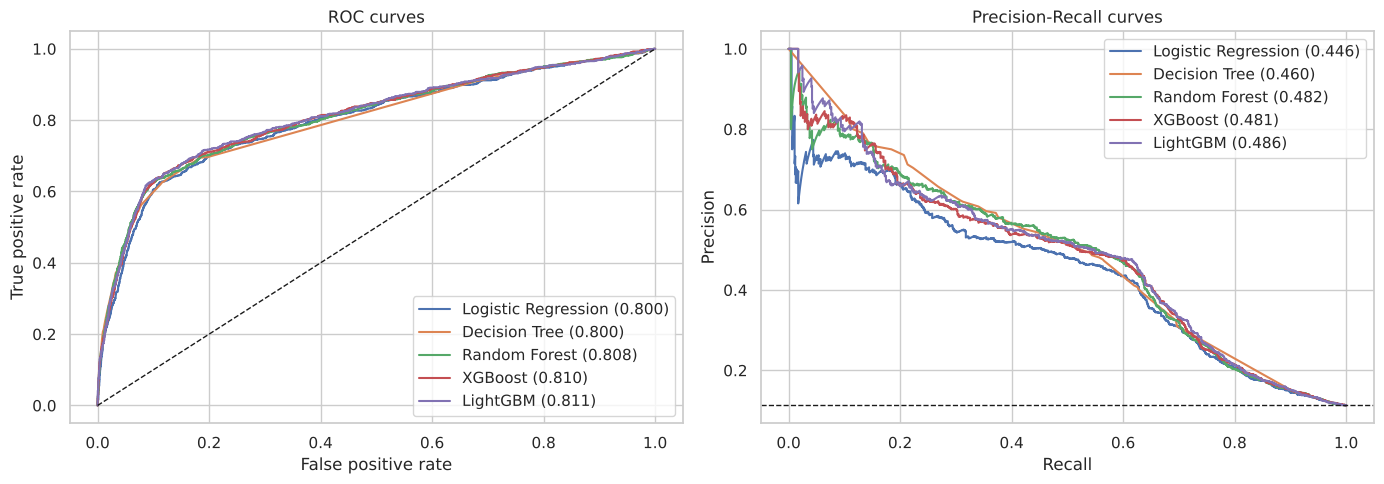

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, pr in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, pr); axes[0].plot(fpr, tpr, label=f'{n} ({roc_auc_score(y_test, pr):.3f})')
    p_, r_, _ = precision_recall_curve(y_test, pr); axes[1].plot(r_, p_, label=f'{n} ({average_precision_score(y_test, pr):.3f})')
axes[0].plot([0,1],[0,1],'k--', lw=1); axes[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate'); axes[0].legend()
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1); axes[1].set(title='Precision-Recall curves', xlabel='Recall', ylabel='Precision'); axes[1].legend()
plt.tight_layout(); plt.show()

## 2.5 Tuning the best candidate

In [19]:
best_name = results.index[0]
print('Tuning:', best_name)
param_space = {
    'XGBoost':  {'model__n_estimators': [200, 300, 500], 'model__max_depth': [3, 4, 5, 6], 'model__learning_rate': [0.02, 0.05, 0.1],
                 'model__min_child_weight': [1, 5, 10], 'model__subsample': [0.7, 0.8, 1.0], 'model__colsample_bytree': [0.6, 0.8, 1.0]},
    'LightGBM': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [3, 4, 5, 6], 'model__learning_rate': [0.02, 0.05, 0.1],
                 'model__num_leaves': [15, 31, 63], 'model__min_child_samples': [20, 50, 100], 'model__colsample_bytree': [0.6, 0.8, 1.0]},
    'Random Forest': {'model__n_estimators': [300, 500], 'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [3, 5, 10, 20]},
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'Decision Tree': {'model__max_depth': [4, 6, 8], 'model__min_samples_leaf': [20, 50, 100]},
}[best_name]
search = RandomizedSearchCV(pipes[best_name], param_space, n_iter=12, scoring='average_precision', cv=3,
                            random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)
print('Best params:', search.best_params_, '| CV PR-AUC:', round(search.best_score_, 4))

Tuning: LightGBM


Best params: {'model__num_leaves': 15, 'model__n_estimators': 200, 'model__min_child_samples': 100, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0} | CV PR-AUC: 0.4658


Tuned LightGBM on test set
ROC-AUC            0.8126
PR-AUC             0.4864
Accuracy           0.8779
Precision (yes)    0.4675
Recall (yes)       0.6045
F1 (yes)           0.5273
Threshold          0.6477
dtype: float64


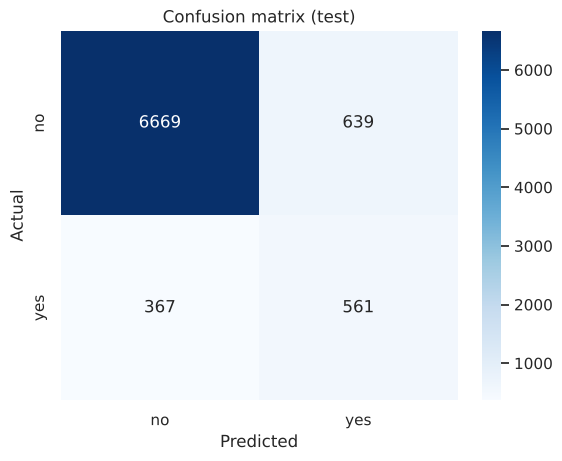

In [20]:
tuned = search.best_estimator_
tuned_cv = cross_val_predict(tuned, X_train, y_train, cv=skf, method='predict_proba')[:, 1]
thr_final = best_threshold(y_train, tuned_cv)
pr = tuned.predict_proba(X_test)[:, 1]; pred = (pr >= thr_final).astype(int)
final = pd.Series({'ROC-AUC': roc_auc_score(y_test, pr), 'PR-AUC': average_precision_score(y_test, pr),
                   'Accuracy': accuracy_score(y_test, pred), 'Precision (yes)': precision_score(y_test, pred),
                   'Recall (yes)': recall_score(y_test, pred), 'F1 (yes)': f1_score(y_test, pred), 'Threshold': thr_final}).round(4)
print(f'Tuned {best_name} on test set'); print(final)
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no','yes'], yticklabels=['no','yes'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test)'); plt.show()

## 2.6 What does the marketing team gain? (decile lift)
Customers are ranked by predicted probability and split into 10 equal groups. If the model is useful, the top deciles should contain far more subscribers than average.

,customers,subscribers,rate,lift,cum_%_of_all_subscribers
decile,,,,,
1,824,442,53.6,4.76,47.6
2,824,175,21.2,1.88,66.5
3,823,73,8.9,0.79,74.4
4,824,43,5.2,0.46,79.0
5,823,39,4.7,0.42,83.2
6,824,46,5.6,0.50,88.1
7,823,31,3.8,0.33,91.5
8,824,31,3.8,0.33,94.8
9,823,22,2.7,0.24,97.2


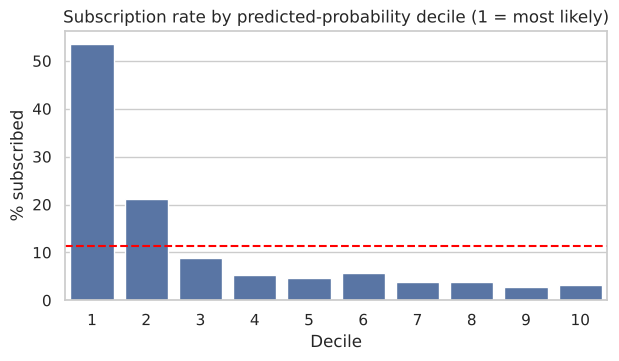

In [21]:
lift = pd.DataFrame({'p': pr, 'y': y_test.values}).sort_values('p', ascending=False).reset_index(drop=True)
lift['decile'] = pd.qcut(lift.index, 10, labels=range(1, 11))
g = lift.groupby('decile').agg(customers=('y', 'size'), subscribers=('y', 'sum'), rate=('y', 'mean'))
g['lift'] = (g['rate'] / lift['y'].mean()).round(2)
g['cum_%_of_all_subscribers'] = (g['subscribers'].cumsum() / g['subscribers'].sum() * 100).round(1)
g['rate'] = (g['rate'] * 100).round(1)
display(g)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=g.index, y=g['rate'], ax=ax); ax.axhline(lift['y'].mean()*100, color='red', ls='--')
ax.set(title='Subscription rate by predicted-probability decile (1 = most likely)', xlabel='Decile', ylabel='% subscribed'); plt.show()

## 2.7 Which features drive the prediction?

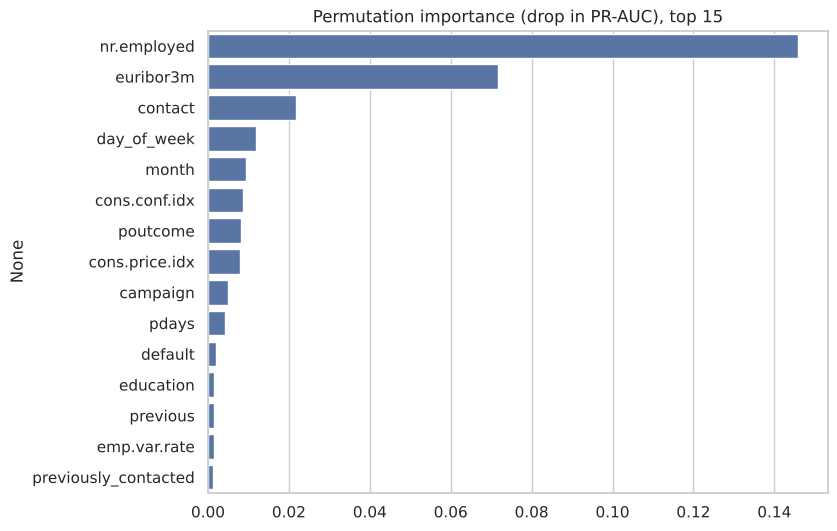

nr.employed       0.1460
euribor3m         0.0718
contact           0.0218
day_of_week       0.0118
month             0.0093
cons.conf.idx     0.0087
poutcome          0.0082
cons.price.idx    0.0080
campaign          0.0050
pdays             0.0043
dtype: float64

In [22]:
perm = permutation_importance(tuned, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); sns.barplot(x=imp.values[:15], y=imp.index[:15], orient='h')
plt.title('Permutation importance (drop in PR-AUC), top 15'); plt.show()
imp.head(10).round(4)

## 2.8 Benchmark only: what if `duration` were allowed?
This run is **not** a usable model (duration is unknown before the call). It only shows how much of the apparent performance would come from leakage.

In [23]:
Xb = engineer(data.drop(columns=['y']), drop_duration=False)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cat_b = Xb.select_dtypes('object').columns.tolist(); num_b = [c for c in Xb.columns if c not in cat_b]
prep_b = ColumnTransformer([('num', StandardScaler(), num_b), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_b)])
bench = Pipeline([('prep', prep_b), ('model', tuned.named_steps['model'].__class__(**tuned.named_steps['model'].get_params()))])
bench.fit(Xb_tr, yb_tr); pb = bench.predict_proba(Xb_te)[:, 1]
pd.DataFrame({'ROC-AUC': [roc_auc_score(yb_te, pb), roc_auc_score(y_test, pr)],
              'PR-AUC': [average_precision_score(yb_te, pb), average_precision_score(y_test, pr)]},
             index=['With duration (leaky benchmark)', 'Without duration (realistic)']).round(4)

,ROC-AUC,PR-AUC
With duration (leaky benchmark),0.9519,0.6697
Without duration (realistic),0.8126,0.4864


# 3. Suggestions for the Bank Marketing Team (Task 3)

The recommendations below come from the EDA and the model (Sections 1 and 2). Rates are observed subscription rates in the historical data; they show association, not proof of cause, so test changes on a small batch before scaling.

**1. Call the highest-scoring customers first.** Ranked by the model, the top 10% of customers subscribed at 53.6% (4.8x the average) and the top 20% contained about two-thirds of all subscribers. Calling the top 30–40% would reach roughly three-quarters to four-fifths of likely buyers while skipping most of the unproductive calls. Where on the list to stop depends on the cost of a call versus the value of a deposit.

**2. Start with warm leads.** Clients whose previous campaign succeeded subscribed 65% of the time. Re-contact these clients before anyone else, and treat a previous *failure* (14%) as a mildly better prospect than a never-contacted client (9%).

**3. Prefer mobile numbers.** Cellular contacts converted at nearly three times the landline rate (14.7% vs 5.2%). Collect mobile numbers where possible and prioritise them.

**4. Target segments that respond better.** Retirees, students and customers aged 60+ or under 25 show the highest rates. Consider tailored offers (e.g. savings products for retirees, starter deposits for students). Blue-collar and services customers respond least, so they are better served by cheaper channels than by long call lists.

**5. Spread calls across the year.** Most calls were made in May, when the rate was only 6.4%, while March, September, October and December converted at 44–51% on small volumes. The low-volume months may have been better-targeted calls, so run a pilot that moves some volume there before concluding that the month itself is the cause.

**6. Cap repeat attempts.** The subscription rate drops from 13% on the first contact to about 4% beyond the 8th. A limit of about 3–4 attempts per customer would free agent time for new leads.

**7. Plan around the economy.** Campaigns ran far better when interest rates (euribor) were low (24% vs 4.8% when they were above 4). Time larger pushes for periods that look like these and keep volume low when conditions are unfavourable.

**8. Invest in call quality.** Call duration was by far the strongest single signal (the benchmark in Section 2.8 jumps from ROC-AUC 0.81 to 0.95). It cannot be used to choose whom to call, but it shows that the conversation itself matters: train agents on opening the call, handling objections and the offer, and track duration and outcome together.

**9. Use the model as a living tool.** Re-score the customer base before each campaign, monitor lift per decile, and retrain periodically, since the economic environment that shaped this data keeps changing.

# 4. Model Comparison Report

Five model families were trained on the same preprocessed data (duration excluded) and compared with 5-fold stratified CV on the training set, then once on a held-out 20% test set. The decision threshold for each was chosen on cross-validated training predictions, never on the test set. The table at the end of this section shows the final test results.

| Model | Test ROC-AUC | Test PR-AUC | Recall (yes) | Precision (yes) | F1 (yes) |
|---|---|---|---|---|---|
| **LightGBM** | 0.811 | **0.486** | 0.600 | 0.479 | 0.533 |
| LightGBM (tuned, 12-trial search) | 0.813 | 0.486 | 0.605 | 0.468 | 0.527 |
| Random Forest | 0.808 | 0.482 | 0.589 | 0.477 | 0.527 |
| XGBoost | 0.810 | 0.481 | 0.593 | 0.481 | 0.531 |
| Decision Tree | 0.800 | 0.460 | 0.557 | 0.481 | 0.516 |
| Logistic Regression | 0.800 | 0.446 | 0.559 | 0.460 | 0.505 |

**Reading the results**
- The three boosted/ensemble models (LightGBM, XGBoost, Random Forest) are practically tied, within about 0.005 of each other on PR-AUC, which is within normal noise for this test-set size. Logistic Regression and the single Decision Tree are clearly behind on PR-AUC.
- Hyperparameter tuning did not improve the test PR-AUC (0.486 both), so the default LightGBM settings are already close to what this data allows.
- Accuracy (about 88%) is nearly identical for every model and for a model that always says "no" (88.7%), so it was not used to choose a winner.
- The ceiling is limited by the features, not the algorithm: without `duration`, the same model scores ROC-AUC 0.81, against 0.95 when the leaky `duration` column is included (benchmark only).

**Recommendation for production: LightGBM** (with a decision threshold around 0.65 from cross-validation). It has the best PR-AUC, trains quickly, handles the mix of features well, and its decile lift (top decile 4.8x, top 20% of customers capturing about two-thirds of subscribers) is directly usable for ranking call lists. Logistic Regression is a reasonable interpretable fallback if explainability to regulators matters more than the last bit of accuracy.

**Caveats before deployment**
- The 0.65 threshold maximises F1; if a call is cheap relative to a deposit's value, lower the threshold to catch more subscribers at the cost of more wasted calls.
- The split here is random, but the data is ordered in time and the top features (`nr.employed`, `euribor3m`) partly act as proxies for the calendar period. Before deployment, validate with a time-based split (train on earlier months, test on later) to see performance on a genuinely new period.

In [24]:
summary = results.copy()
summary.loc[f'{best_name} (tuned)'] = final
summary.round(4).sort_values('PR-AUC', ascending=False)

,ROC-AUC,PR-AUC,Accuracy,Precision (yes),Recall (yes),F1 (yes),Threshold
Model,,,,,,,
LightGBM,0.8111,0.4864,0.8813,0.4785,0.6002,0.5325,0.6466
LightGBM (tuned),0.8126,0.4864,0.8779,0.4675,0.6045,0.5273,0.6477
Random Forest,0.8079,0.4823,0.8809,0.4769,0.5894,0.5272,0.6326
XGBoost,0.8098,0.4807,0.8820,0.4808,0.5927,0.5309,0.6604
Decision Tree,0.7998,0.4597,0.8823,0.4809,0.5571,0.5162,0.6924
Logistic Regression,0.7999,0.4457,0.8764,0.4601,0.5593,0.5049,0.6746


# 5. Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | **Target leakage from `duration`** | Excluded it from the production model; ran it once as a labelled benchmark | Call length is only known after the call, so using it would give a model that cannot be used in practice (ROC-AUC 0.95 vs 0.81) |
| 2 | **Class imbalance** (11.3% yes) | Class weights (`balanced`, `scale_pos_weight`), stratified train/test and CV splits, and threshold tuning | Keeps all real data without creating synthetic rows, and protects the minority class from being ignored |
| 3 | **Misleading accuracy** | Judged models by ROC-AUC, PR-AUC, recall, precision and F1 for the "yes" class, plus decile lift | An "always no" model scores 88.7% accuracy; the business needs to *find* subscribers |
| 4 | **Hidden missing values** (`unknown` in six columns, up to ~21% in `default`) | Kept `unknown` as its own category | Deleting rows would lose data, imputing would invent information, and `unknown` is itself informative (`default = unknown` converts at 5.2% vs 12.9% for `no`) |
| 5 | **`pdays = 999` placeholder** | Created a `previously_contacted` flag and set the day count to 0 for those rows | A value of 999 would be read as a real number of days and distort scaling and linear models |
| 6 | **Skewed counts and outliers** (`campaign` up to 56, `previous`) | Capped `campaign` at its 99th percentile (14) and applied `log1p` to `previous` | Reduces the pull of a few extreme clients on Logistic Regression while keeping the information |
| 7 | **Multicollinearity** (`euribor3m`, `emp.var.rate`, `nr.employed` correlated 0.91–0.97) | Kept all three, relied on regularised Logistic Regression and tree-based models, and read importances with caution | Tree models tolerate it; importance is shared across the group, so the exact ranking among those three should not be over-interpreted |
| 8 | **Duplicate rows** (12) | Removed before splitting | Prevents identical rows appearing in both train and test |
| 9 | **Choosing the threshold without cheating** | Selected it on cross-validated training predictions; the test set was used once | Avoids an optimistic test score from tuning on the test data |
| 10 | **Fair model comparison and tuning cost** | Same preprocessing pipeline inside every model (so scaling/encoding is fitted on training folds only), 5-fold CV, and a 12-trial randomised search for the best model | Prevents leakage between folds and keeps run time reasonable; the search found no gain over defaults, which is itself a finding |
| 11 | **Time-ordered data** | Used a stratified random split and flagged the limitation | Macro-economic features partly stand in for the calendar period, so a time-based validation is the recommended next step before production |
| 12 | **Unequal monthly volumes** (May: 13,769 calls; December: 182) | Reported both rate and volume; recommended a pilot rather than a firm conclusion | High rates on small samples may reflect who was called rather than the month itself |